### Undersampling + Overlap

### <i> Using ENN

####  <strong style='color:red'> WARNING: </strong> VERY AGGRESSIVE way to deal with overlap

In [1]:
# Let's open up the diamonds.csv dataset again.

# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Loading the dataset
df = pd.read_csv(
    "../diabetes.csv",
    index_col=0
)


# Binary encoding the `diabetes` column
variables = ['diabetes']

df[variables] = df[variables].replace({
    'neg': 0,
    'pos': 1
})

df["diabetes"] = df["diabetes"].astype(int)

df

,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
pregnant,,,,,,,,
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1
3,78,50,32,88,31.0,0.248,26,1
2,197,70,45,543,30.5,0.158,53,1
1,189,60,23,846,30.1,0.398,59,1
...,...,...,...,...,...,...,...,...
0,181,88,44,510,43.3,0.222,26,1
1,128,88,39,110,36.5,1.057,37,1
2,88,58,26,16,28.4,0.766,22,0


---

### The problem

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">


Previously, we used undersampling (`ClusterCentroids` and `RandomUnderSampler`) to fix the distribution to our liking, but that's not the only way we can use undersampling. There is an undersampling technique which allows us to mitigate overlap instead of shaping distributions.


##### `ENN (Edited Nearest Neighbor)`

ENN undersamples the data to eliminate rows which contain noise + overlap

It uses the distance from its' neighbors to determine whether to keep the row or not. 

It does this by having rows check it's neighbors, and seeing whether their attributes and classes are the same. If they are not, depending on the parameters, remove the row.

</div>


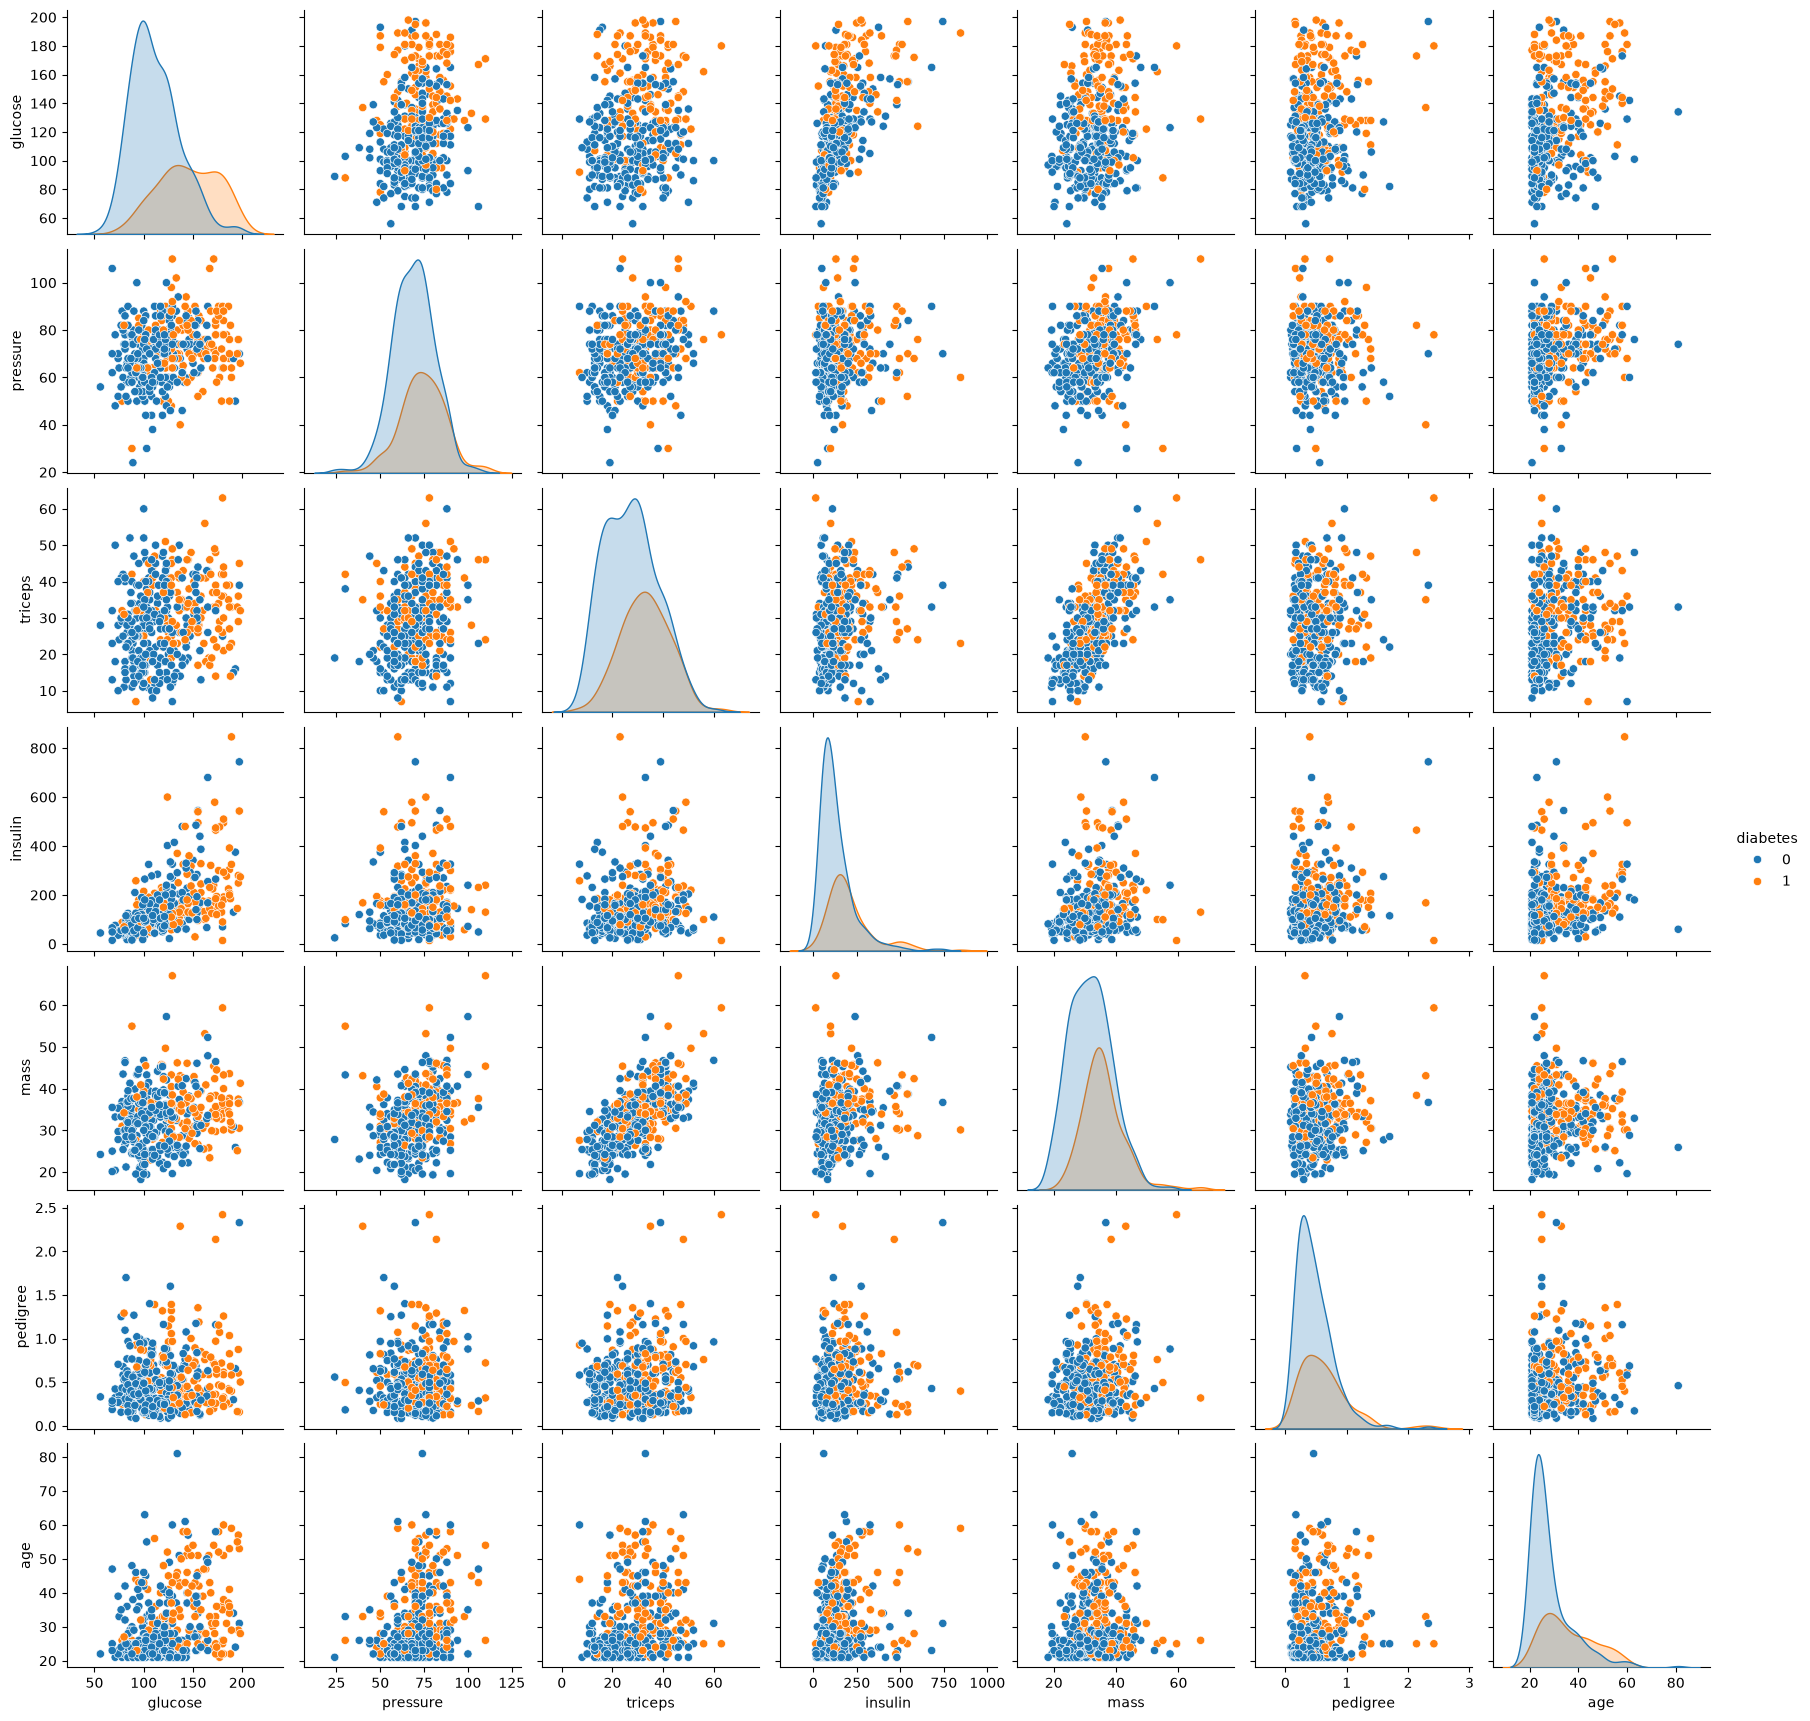

In [2]:
# Here we can see a significant amount of overlap at every turn.
sns.pairplot(df, hue="diabetes")

# First, we ask ourselves this:
# Does this reflect reality? Probably but we can also expect the ML model
# to be VERY confused here. This may reflect reality but this might be 
# too much overlap for a ML model to handle! So let's cull some overlap, 
# just enough so the ML model can handle it.

In [3]:
df.shape

(392, 8)

In [4]:
from imblearn.under_sampling import EditedNearestNeighbours

# X y split
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# Initializing ENN.
enn = EditedNearestNeighbours(
    n_neighbors=4,
    kind_sel="all"  
)

# Resample using ENN
X_clean, y_clean = enn.fit_resample(X, y)

# Make a new dataframe and add y_clean back into it.
df_undersampled = pd.DataFrame(X_clean)
df_undersampled["diabetes"] = y_clean

# If you want a less-harsh overlap removal, consider putting the `kind_sel` parameter to `mode`.
# `kind_sel` = `mode` ---> it will use majority_vote instead (from it's `n_neighbors`)
# `kind_sel` = `all` ---> if ANY neighbors say it doesn't fit, remove it. 


In [5]:
# Let's check how many rows it kept

df_undersampled.shape
# Quite a cull... Might be too aggressive. But we didn't have much rows to begin with.
# It's just an example anyways.

(249, 8)

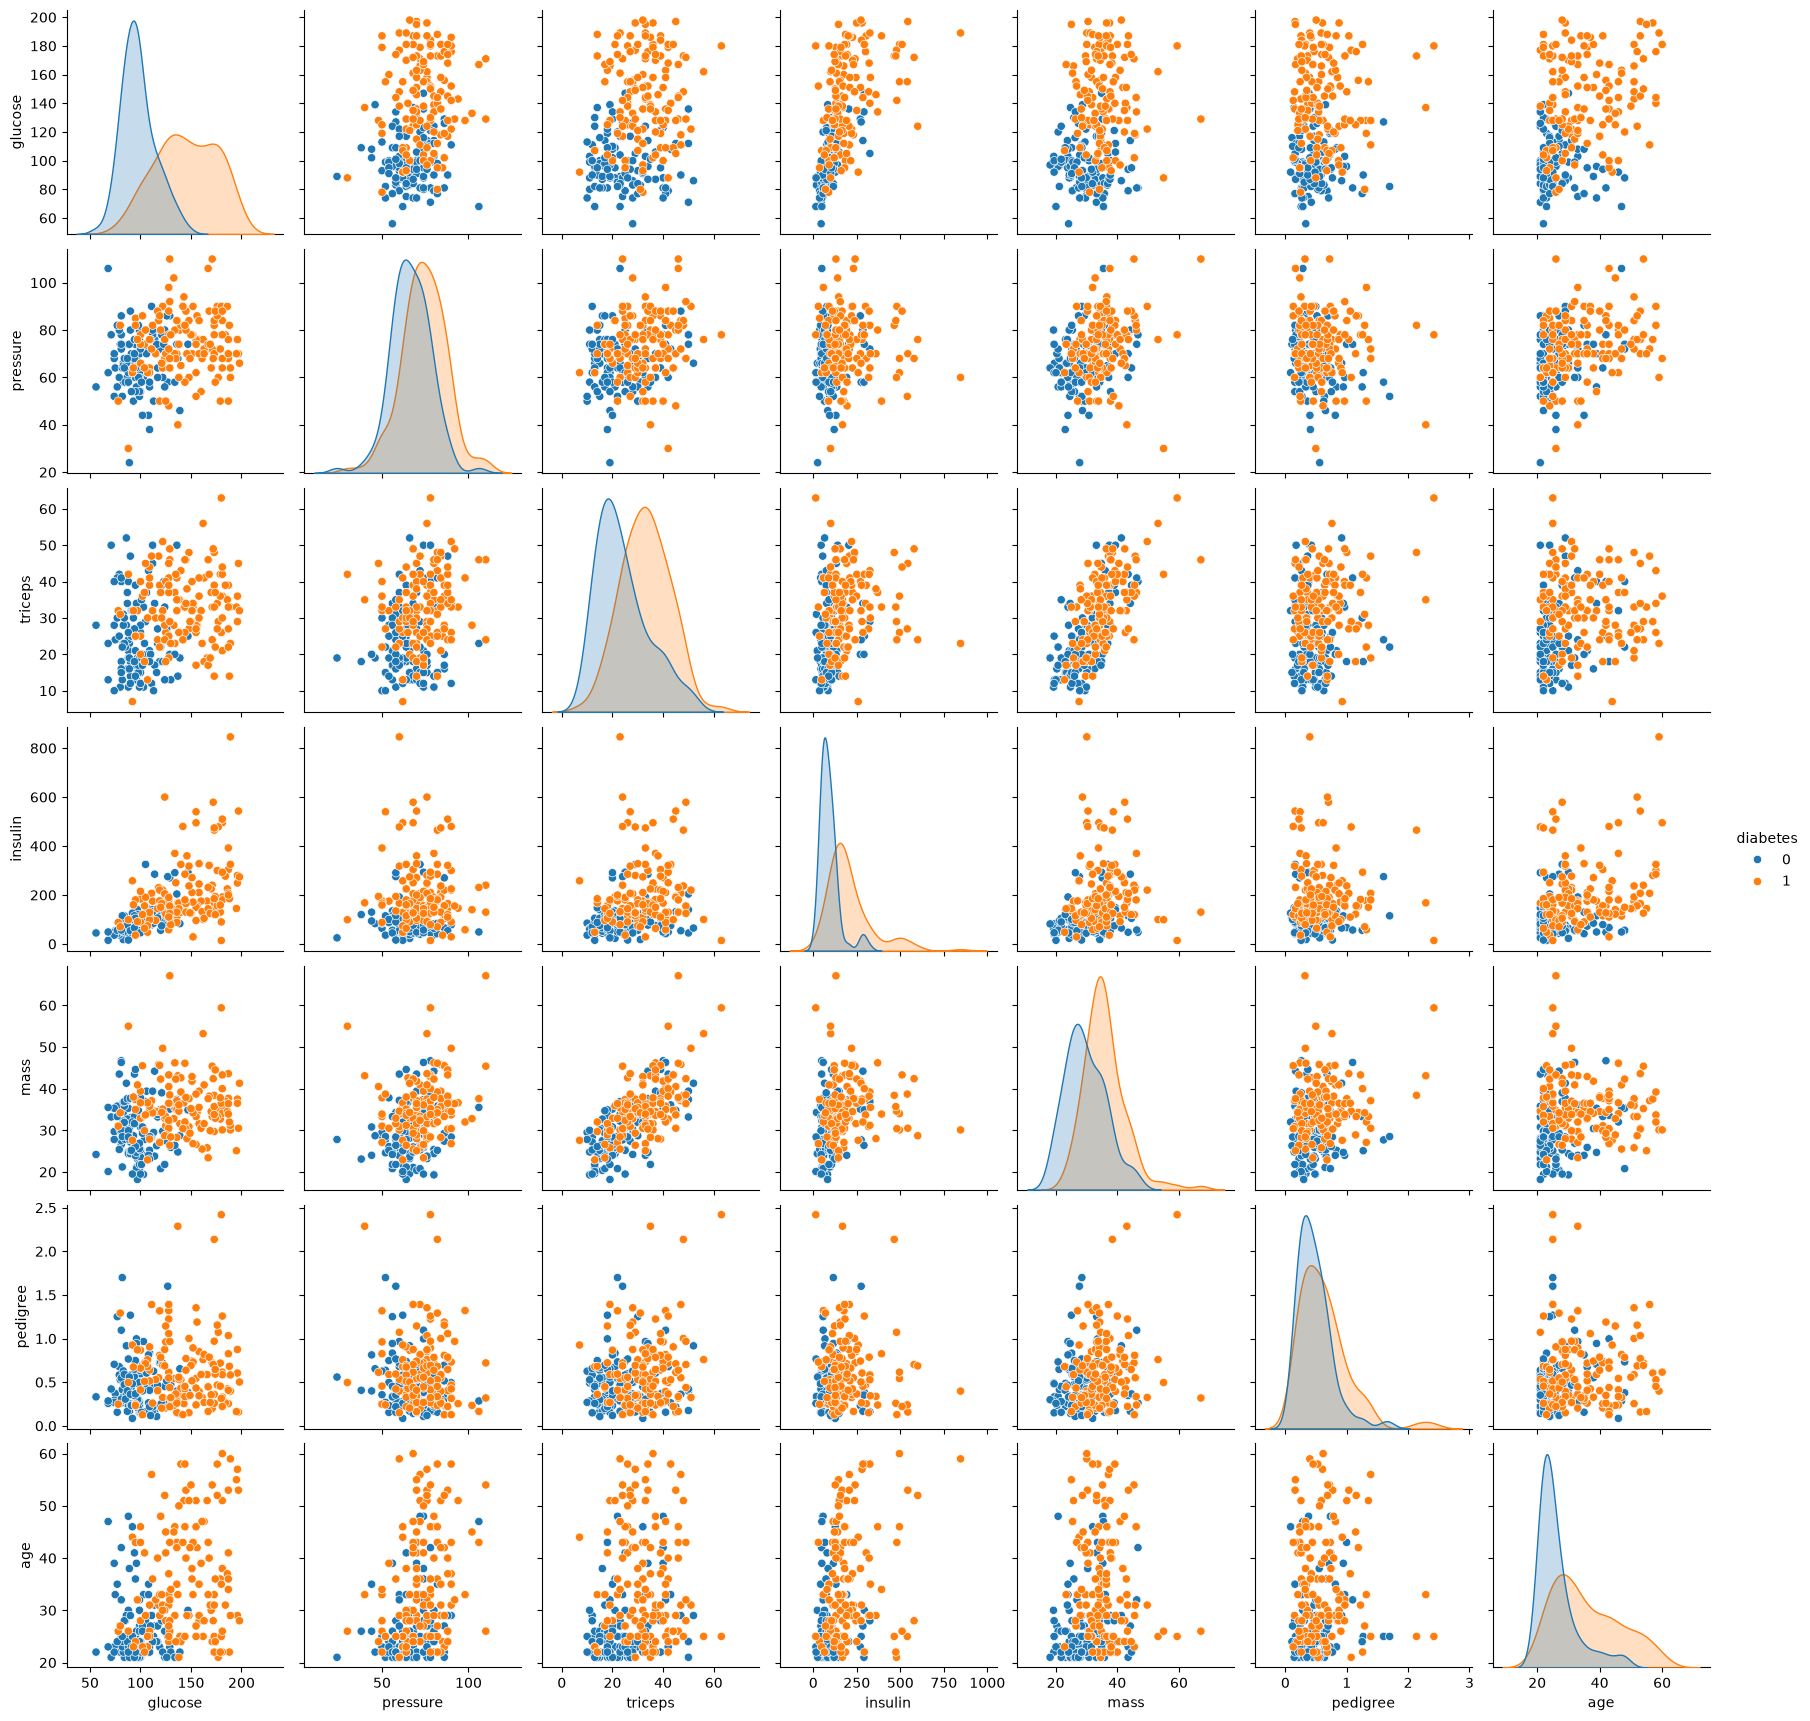

In [6]:
sns.pairplot(df_undersampled, hue="diabetes")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

* We see significantly less overlap than before, but some still exists to maintain the 'real-ness'

<strong style='color:red ; background-color:black;'> How much elimination of overlap is permissable until the model doesn't work in real life anymore? </strong>

Often times, this is a extremely delicate balance (especially with heavy overlap) that is impossible to accurately determine without intuition. 

With ENN -- we could make it look absolutely overlap-less and perfect -- but it would tank in production. That's the danger of ENN.


</div>

---

### HOW NOT TO USE ENN

In [7]:
from imblearn.under_sampling import EditedNearestNeighbours

# X y split
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# Initializing ENN.
enn = EditedNearestNeighbours(
    n_neighbors=10,   # WE RAMP THIS UP
    # Remove the row when the majority of it's neighbors disagree with its class
    kind_sel="all"   # "all" is also a parameter (If any neighbor disagrees, remove it.)
)

# Resample using ENN
X_clean, y_clean = enn.fit_resample(X, y)

# Make a new dataframe and add y back into it again.
df_undersampled_overkill = pd.DataFrame(X_clean)
df_undersampled_overkill["diabetes"] = y_clean


In [8]:
# Let's check the number of rows again
df_undersampled_overkill.shape

# Aaaaand you can see it dropped virtually all our data.

(183, 8)

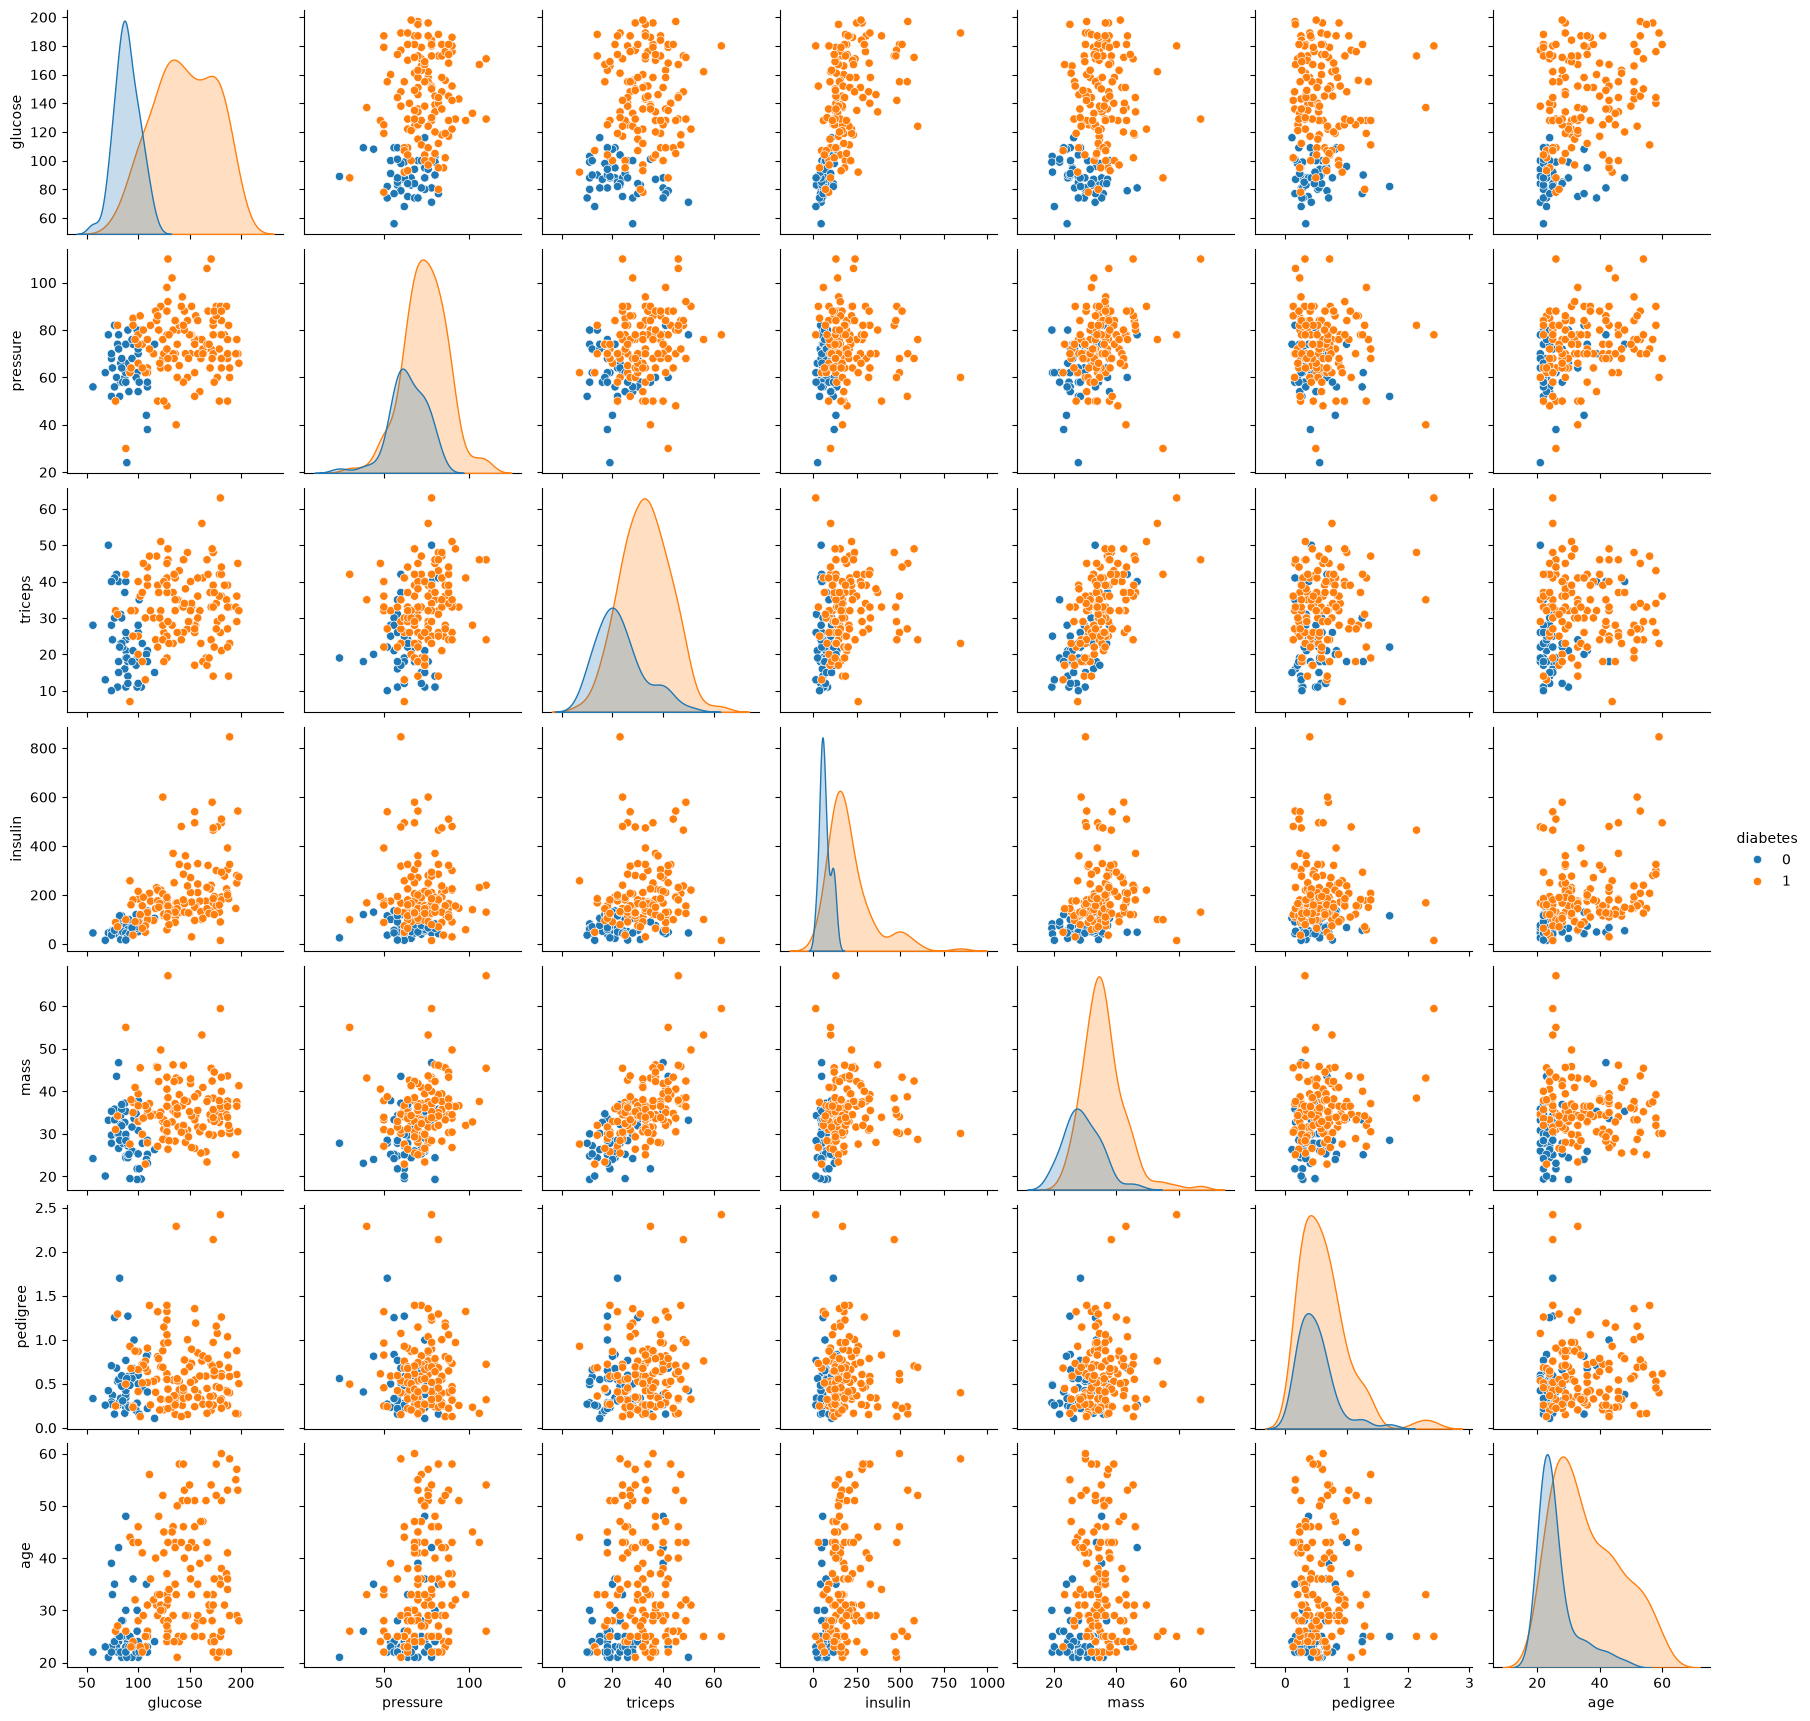

In [9]:
# And what's more, you see it also completely annihilated the reality of the dataset.
sns.pairplot(df_undersampled_overkill, hue="diabetes")

# Ultimately, it all falls under experimentation.

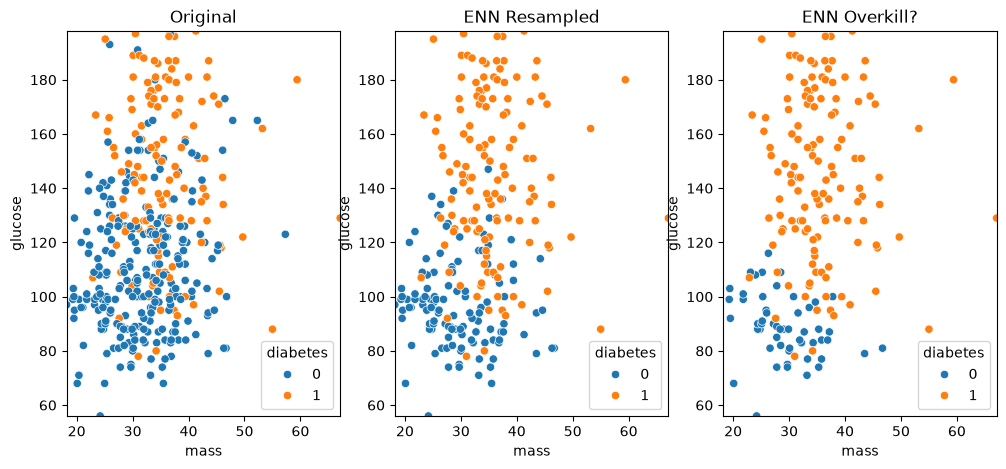

In [10]:
import matplotlib.pyplot as plt

x = "mass"
y= "glucose"
hue_c = "diabetes"

# Create canvas, two subplots -- side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Make two scatterplots on the canvas
sns.scatterplot(df, x=x, y=y, hue=hue_c, ax=axes[0])
sns.scatterplot(df_undersampled, x=x, y=y, hue=hue_c, ax=axes[1])
sns.scatterplot(df_undersampled_overkill, x=x, y=y, hue=hue_c, ax=axes[2])

# Get common axis limits from both datasets
x_min = min(df[x].min(), df_undersampled[x].min())
x_max = max(df[x].max(), df_undersampled[x].max())

y_min = min(df[y].min(), df_undersampled[y].min())
y_max = max(df[y].max(), df_undersampled[y].max())

# Apply the same limits to both plots
for ax in axes:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

# Set titles 
axes[0].set_title("Original")
axes[1].set_title("ENN Resampled")
axes[2].set_title("ENN Overkill?")
plt.show()
